# Motivation Plots

In [1]:
# !pip install seaborn

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import pandas as pd
import numpy as np
import math, os, re, sys
from typing import Dict, List, Optional, Tuple
import warnings, glob
import scienceplots

In [3]:
# ── Shared style ────────────────────────────────────────────────────────────
plt.style.use(['science', 'grid', 'no-latex', 'high-contrast'])
plt.rcParams['pdf.fonttype'] = 42   # TrueType, not Type 3
plt.rcParams['ps.fonttype'] = 42

# Engine color/hatch palette (MMap=blue, IOUring=orange, SCISSOR=green)
ENGINE_STYLE = {
    'MMap':    {'color': '#1f77b4', 'hatch': '//'},
    'IOUring': {'color': '#ff7f0e', 'hatch': '..'},
    'SCISSOR': {'color': '#2ca02c', 'hatch': 'xx'},
}

FONT = {'title': 13, 'axis': 12, 'tick': 10, 'annot': 9, 'legend': 9}
FIG_SIZE_DEFAULT = (6, 3)
FIG_SIZE_WIDE    = (8, 4)
FIG_SIZE_SMALL   = (3.5, 2.5)

# High-contrast palette for general use
HC_COLORS = [
    '#000000', '#E69F00', '#56B4E9', '#009E73',
    '#F0E442', '#0072B2', '#D55E00', '#CC79A7',
    '#1f77b4', '#2ca02c'
]

fig_dir = "../figures"
os.makedirs(fig_dir, exist_ok=True)

## Helper Functions

In [4]:
def proc_comp(name):
    df = pd.read_csv(name)
    # Average the measured per-run values per (IOP, Chunk size).
    agg = df.groupby(['IOP', 'Chunk size (B)'], as_index=False)[
        ['Total size (B)', 'Load time (s)', 'Compare time (s)', 'Throughput (GiB/s)']
    ].mean()

    agg['total_io_size (KiB)'] = (agg['Total size (B)'] / 1024).astype(int)
    agg['Chunk size (KiB)'] = (agg['Chunk size (B)'] / 1024).astype(int)
    df = agg.rename(columns={
        'IOP': 'iop (requests)',
        'Load time (s)': 'io_time (s)',
        'Compare time (s)': 'comp_time (s)',
        'Throughput (GiB/s)': 'throughput (gib/s)',
        'Chunk size (KiB)': 'chunk_size (kib)',
        'total_io_size (KiB)': 'batch size (KiB)',
    })
    df = df[['iop (requests)', 'chunk_size (kib)', 'batch size (KiB)', 'io_time (s)', 'comp_time (s)', 'throughput (gib/s)']]
    return df


def combine(files, sizes):
    dfs = []
    for i in range(len(files)):
        dfs.append(proc_comp(files[i]))
        dfs[i]["total_size"] = sizes[i]
    return pd.concat(dfs, ignore_index=True)


def load_offsets(path: str) -> np.ndarray:
    """Load offsets from a whitespace-separated numeric file and return a 1D uint64 array."""
    try:
        arr = np.loadtxt(path, dtype=np.uint64)
    except Exception as e:
        raise RuntimeError(f"failed to read offsets from {path}: {e}")
    if arr.ndim != 1:
        arr = arr.flatten()
    return arr


def find_file(base_path: str, sim: str, filename: str) -> Optional[str]:
    p1 = os.path.join(base_path, sim, filename)
    if os.path.exists(p1):
        return p1
    p2 = os.path.join(base_path, filename)
    if os.path.exists(p2):
        return p2
    return None


def get_offset_distances_kb(offsets: np.ndarray, block_size: int) -> np.ndarray:
    jumps_bytes = np.diff(offsets.astype(np.int64))
    abs_jumps_bytes = np.abs(jumps_bytes)
    jumps_kb = abs_jumps_bytes / 1024.0
    mask = (jumps_kb >= 1) & (jumps_kb <= 64)
    return jumps_kb[mask]

In [5]:
def plot_thrpt_line(df: pd.DataFrame, type: str, src: str,
                    figsize=FIG_SIZE_DEFAULT, save_dir: Optional[str] = None):

    required = {'iop (requests)', 'throughput (gib/s)', 'total_size'}
    if not required.issubset(df.columns):
        raise ValueError(f"DataFrame must contain columns: {required}")

    fig, ax = plt.subplots(figsize=figsize)

    xticks = [4, 16, 64, 256, 1024, 4096, 8192, 16384, 65536, 262144]
    df = df[
        (df['iop (requests)'].isin(xticks)) &
        (df['total_size'].isin([1, 2]))
    ]

    linestyles = {
        1: (0, ()),
        2: (0, (4, 2)),
    }
    markers = {
        1: 'o',
        2: 's',
    }
    colors = [0, -4]

    x_pos = {v: i for i, v in enumerate(xticks)}

    for total_size, group in df.groupby('total_size'):
        group_sorted = group.sort_values(by='iop (requests)')
        ax.plot(
            [x_pos[v] for v in group_sorted['iop (requests)']],
            group_sorted['throughput (gib/s)'],
            label=f"{total_size} GB",
            linestyle=linestyles[total_size],
            marker=markers[total_size],
            color=HC_COLORS[colors[total_size-1]],
            linewidth=2,
            markersize=4,
        )

    ax.set_xticks(range(len(xticks)))

    def fmt_k(v):
        val = xticks[int(v)]
        if val >= 1024:
            return f"{val // 1024}K"
        return str(val)

    ax.set_xticklabels([fmt_k(i) for i in range(len(xticks))], fontsize=FONT['tick'])
    ax.set_xlabel(f'Number of IOPs', fontsize=FONT['axis'])
    ax.set_ylabel(f'{src} Throughput (GB/s)', fontsize=FONT['axis'])
    ax.legend(title='Total Size', loc='best', frameon=True)
    ax.grid(True, linestyle=':', alpha=0.4)
    ax.tick_params(axis='y', labelsize=FONT['tick'])

    plt.tight_layout()

    if save_dir:
        fname_save = os.path.join(save_dir, f"{src}_io_bench.pdf")
        fig.savefig(fname_save, dpi=600)
        print(f"Saved figure to {fname_save}")

    plt.show()

In [6]:
def plot_offset_distributions_violin_group(
    base_path: str,
    sims: list,
    errors: list,
    chunk_sizes: list,
    figsize=(7, 3),
    save_dir: Optional[str] = None
):
    fixed_error = "1e-7"
    fixed_chunk = 4096
    err_mapping = {'1e-3':r"$10^{-3}$", '1e-5':r"$10^{-5}$", '1e-7':r"$10^{-7}$"}

    for sim in sims:
        fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True)

        # Violin: per chunk size
        ax = axes[0]
        data = []
        labels = []

        for chunk in chunk_sizes:
            fname = f"{base_path}/{sim}/m000p.mpirestart-combined-0-10.dat_{chunk}_{fixed_error}.txt"
            fullpath = find_file(base_path, sim, fname)
            if fullpath is None:
                continue
            offsets = load_offsets(fullpath)
            jumps_kb = get_offset_distances_kb(offsets, chunk)
            if len(jumps_kb) > 0:
                data.append(jumps_kb)
                labels.append(f"{chunk // 1024} KB")

        if data:
            parts = ax.violinplot(data, widths=0.6, showmeans=False, showmedians=True, showextrema=False)
            for pc in parts["bodies"]:
                pc.set_facecolor(HC_COLORS[-1])
                pc.set_edgecolor("black")
                pc.set_alpha(0.7)

        ax.set_xticks(np.arange(1, len(labels) + 1))
        ax.set_xticklabels(labels, fontsize=FONT['tick'])
        ax.set_ylabel("Offset Distance (KB)", fontsize=FONT['axis'])
        ax.set_xlabel(r"IOP size (Error = $10^{-7}$)", fontsize=FONT['axis'])
        ax.set_ylim(0, 64)
        ax.grid(axis="y", linestyle="--", alpha=0.6)

        # Violin: per error
        ax = axes[1]
        data = []
        labels = []

        for err in errors:
            fname = f"{base_path}/{sim}/m000p.mpirestart-combined-0-10.dat_{fixed_chunk}_{err}.txt"
            fullpath = find_file(base_path, sim, fname)
            if fullpath is None:
                continue
            offsets = load_offsets(fullpath)
            jumps_kb = get_offset_distances_kb(offsets, fixed_chunk)
            if len(jumps_kb) > 0:
                data.append(jumps_kb)
                labels.append(err_mapping[err])

        if data:
            parts = ax.violinplot(data, widths=0.6, showmeans=False, showmedians=True, showextrema=False)
            for pc in parts["bodies"]:
                pc.set_facecolor(HC_COLORS[-2])
                pc.set_edgecolor("black")
                pc.set_alpha(0.7)

        ax.set_xticks(np.arange(1, len(labels) + 1))
        ax.set_xticklabels(labels, fontsize=FONT['tick'])
        ax.set_xlabel("Errors (IOP size = 4 KB)", fontsize=FONT['axis'])
        ax.set_ylim(0, 64)
        ax.grid(axis="y", linestyle="--", alpha=0.6)

        plt.tight_layout(rect=[0, 0, 1, 0.95])

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            fname = os.path.join(save_dir, f"{sim}_violin_err_oft.pdf")
            fig.savefig(fname, dpi=600)
            print(f"Saved figure to {fname}")

        plt.show()

In [7]:
def coalesce_offsets(offsets: np.ndarray, max_gap_chunks: int) -> Tuple[int, int]:
    offsets_sorted = np.sort(offsets)
    num_bins = 0
    unnecessary_chunks = 0
    i = 0
    n = len(offsets_sorted)
    while i < n:
        num_bins += 1
        i += 1
        while i < n:
            gap_chunks = offsets_sorted[i] - offsets_sorted[i-1]
            if gap_chunks <= max_gap_chunks:
                if gap_chunks > 1:
                    unnecessary_chunks += (gap_chunks - 1)
                i += 1
            else:
                break
    return num_bins, unnecessary_chunks


def plot_bins_vs_unnecessary_chunks(
    offsets: np.ndarray, block_size: int, allowed_gaps: List[int],
    title: str = "", save_dir: Optional[str] = None
):
    bins_list = []
    unnecessary_list = []

    for gap in allowed_gaps:
        num_bins, unnecessary = coalesce_offsets(offsets, gap)
        bins_list.append(num_bins)
        unnecessary_list.append((unnecessary * block_size) // (1024 * 1024))

    print(bins_list)
    print(unnecessary_list)
    x = np.arange(len(allowed_gaps))

    # Convert chunk-unit gaps to KB for axis labels
    gap_labels_kb = [gap * block_size // 1024 for gap in allowed_gaps]

    bins_list_K = [count // 1000 for count in bins_list]

    fig, ax1 = plt.subplots(figsize=FIG_SIZE_SMALL)

    ax1.plot(x, bins_list_K, color=HC_COLORS[-2], marker='o', label="IOP Count", linewidth=2)
    ax1.set_xticks(x)
    ax1.set_xticklabels([str(g) for g in gap_labels_kb], fontsize=FONT['tick'])
    ax1.set_xlabel("Gap between offsets (KB)", fontsize=FONT['axis'])
    ax1.set_ylabel("IOP Count (K)", fontsize=FONT['axis'])
    ax1.grid(True, axis='y', linestyle="--", alpha=0.5)

    ax2 = ax1.twinx()
    ax2.plot(x, unnecessary_list, color='tab:red', marker='o', label="Extra Read", linewidth=2, linestyle="--")
    ax2.set_ylabel("Size of extra data (MB)", color='tab:red', fontsize=FONT['axis'])
    ax2.tick_params(axis='y', labelcolor='tab:red')

    lines, labels = [], []
    for ax in [ax1, ax2]:
        l, lab = ax.get_legend_handles_labels()
        lines += l
        labels += lab
    ax1.legend(lines, labels, ncols=2, loc='upper center', bbox_to_anchor=(0.5, 1.25))

    plt.tight_layout()

    if save_dir:
        fname_save = os.path.join(save_dir, f"iop_wastedreads_plot.pdf")
        fig.savefig(fname_save, dpi=600)
        print(f"Saved figure to {fname_save}")

    plt.show()

## Data Loading

In [8]:
dir = "../data/motivation/benchmark_data"

In [9]:
files = [
    f"{dir}/contiguous_io_1_ssd.csv",
    f"{dir}/contiguous_io_2_ssd.csv",
    f"{dir}/contiguous_io_1_pfs.csv",
    f"{dir}/contiguous_io_2_pfs.csv"
]
contiguous_ssd = combine(files[:2], [1, 2])
contiguous_pfs = combine(files[2:], [1, 2])

In [10]:
files = [
    f"{dir}/random_io_1_ssd.csv",
    f"{dir}/random_io_2_ssd.csv",
    f"{dir}/random_io_1_pfs.csv",
    f"{dir}/random_io_2_pfs.csv"
]
random_ssd = combine(files[:2], [1, 2])
random_pfs = combine(files[2:], [1, 2])

## Plots

Saved figure to ../figures/PFS_io_bench.pdf


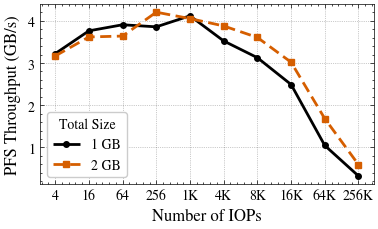

In [11]:
plot_thrpt_line(contiguous_pfs, 'contiguous', 'PFS', figsize=(4, 2.5), save_dir=fig_dir)
# plot_thrpt_line(random_pfs, 'random', 'PFS', figsize=(4, 2.5), save_dir=fig_dir)

In [12]:
# Values plotted in the figure above (GB/s)
plotted_iops = [4, 16, 64, 256, 1024, 4096, 8192, 16384, 65536, 262144]
plotted_df = contiguous_pfs[contiguous_pfs['iop (requests)'].isin(plotted_iops)]
plotted_df.pivot(index='iop (requests)', columns='total_size', values='throughput (gib/s)').round(2)

total_size,1,2
iop (requests),,
4,3.22,3.17
16,3.76,3.62
64,3.91,3.64
256,3.86,4.21
1024,4.12,4.05
4096,3.52,3.88
8192,3.13,3.61
16384,2.49,3.02
65536,1.04,1.68


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


Saved figure to ../figures/np1000_violin_err_oft.pdf


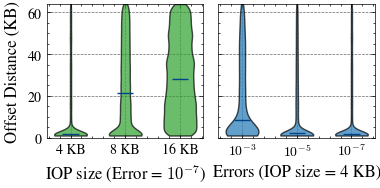

In [13]:
path_to_files = os.path.abspath("../data/motivation/offsets")
sims = ["np1000"]
errors = ["1e-3", "1e-5", "1e-7"]
chunk_sizes = [4096, 8192, 16384, 32768]

plot_offset_distributions_violin_group(
    base_path=path_to_files,
    sims=sims,
    errors=errors,
    chunk_sizes=chunk_sizes,
    figsize=(4, 2.2),
    save_dir=fig_dir
)

[27908, 27139, 25712, 23463, 20038]
[0, np.uint64(3), np.uint64(16), np.uint64(63), np.uint64(216)]


Saved figure to ../figures/iop_wastedreads_plot.pdf


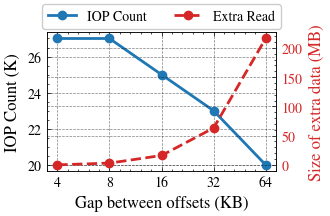

In [14]:
# offsets = load_offsets(f"{path_to_files}/np1000/m000p.mpirestart-combined-0-10.dat_4096_1e-3.txt")
# plot_bins_vs_unnecessary_chunks(
#     offsets,
#     block_size=4096,
#     allowed_gaps=[0, 4, 8, 16, 32],
#     title="np796",
#     save_dir=fig_dir
# )

offsets = load_offsets(f"{path_to_files}/np1000/m000p.mpirestart-combined-0-10.dat_4096_1e-3.txt")
plot_bins_vs_unnecessary_chunks(
    offsets,
    block_size=4096,
    allowed_gaps=[1, 2, 4, 8, 16],
    title="np1000",
    save_dir=fig_dir
)